# End-to-End Retail Analytics & Predictive Intelligence: DMart (MMR Region)

## 1. Business Scenario & Problem Statement

### Business Context
Avenue Supermarts (DMart) operates on a high-throughput, Everyday Low Cost / Everyday Low Price (EDLC–EDLP) retail model, with its densest omnichannel footprint across the Mumbai Metropolitan Region (MMR)—spanning key hubs in **Dadar, Thane, Borivali, Powai, and Panvel**, alongside its digital fulfillment arm, **DMart Ready**. 

With rapid urban competition from quick-commerce platforms and evolving basket compositions across staples, dairy, and personal care, regional management faces a critical challenge: **maintaining high repeat footfall and maximizing basket size without relying on margin-eroding promotional discounts.**

### Core Operational Challenges
1. **Fragmented POS Data:** Raw transactional logs across hypermarkets and app channels suffer from duplicate entries, missing customer demographics, negative pricing anomalies, and inconsistent date formats—preventing unified reporting.
2. **Untargeted Retention Efforts:** Management lacks visibility into which shoppers are quietly lapsing, treating high-value household buyers the same as occasional walk-ins.
3. **Suboptimal Cross-Selling & Inventory Buffers:** Without data-backed aisle adjacency rules or forward-looking monthly demand forecasts, high-velocity staples risk stockouts during peak monthly cycles.

### Analytical Objectives
To solve these challenges, this project builds an end-to-end **Data Engineering, Machine Learning, and Business Intelligence** pipeline designed to answer four strategic questions:
* **Customer Segmentation (K-Means Clustering):** How can we group 1,500 MMR shoppers into actionable behavioral personas based on Recency, Frequency, Monetary (RFM) value, and income?
* **Churn Prediction (Random Forest Classification):** Which customers are at high risk of churning, and what behavioral signals act as the earliest warning indicators?
* **Market Basket Optimization (Association Rule Mining):** Which product pairs exhibit the strongest co-purchasing lift to guide store aisle placement and digital app bundles?
* **Demand Forecasting (Linear Regression):** Based on H1 2026 growth trajectories (Jan–Jun), what is the projected revenue for **July 2026** to guide regional inventory procurement?

# Data load

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [87]:
# raw data load
df = pd.read_csv(r'C:\Users\Home\Documents\projects\dmart\DMart_Raw_Transactions_2026.csv')
print(df.shape)

(38951, 30)


# Data Cleaning

In [88]:
# removing duplicate 
f = df.drop_duplicates()

In [89]:
# remove invalid transaction where Unit_Price is negative or Quantity is zero or negative.
df = df[~((df['Unit_Price'] < 0) | (df['Quantity'] <= 0))].copy()

In [90]:
# To make consistent title-case format
for col in ['Store_City', 'Customer_City', 'Category']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

In [95]:
print(df.shape)

(38058, 30)


In [96]:
# fill in missing values in Age and Membership
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Membership_Tier'] = df['Membership_Tier'].fillna(df['Membership_Tier'].mode()[0])

In [97]:
# to ensure calculation are perfect we recalculate this 
df['Gross_Amount'] = (df['Quantity'] * df['Unit_Price'] * (1 - df['Discount_Pct'] / 100.0)).round(2)
if 'Cost_Price' in df.columns:
    df['Net_Profit'] = (df['Gross_Amount'] - (df['Quantity'] * df['Cost_Price'])).round(2)


In [98]:
print(f"Final Cleaned Shape (No Null Dates): {df.shape}")
print(f"Remaining Missing Dates: {df['Full_Date'].isna().sum()}")

# Save output
df.to_csv('DMart_Cleaned_Transactions_2026.csv', index=False)

Final Cleaned Shape (No Null Dates): (38058, 30)
Remaining Missing Dates: 0


# Exploratory Data Analysis (EDA)

In [101]:
numeric_cols = ['Quantity', 'Unit_Price', 'Discount_Pct', 'Gross_Amount', 'Net_Profit', 'Age', 'Annual_Income']
summary_stats = df[numeric_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
summary_stats = summary_stats.rename(columns={'50%': 'median'})
print(summary_stats.round(2).to_string())

                 count        mean        std       min     median        max
Quantity       38058.0        1.93       0.84       1.0        2.0        4.0
Unit_Price     38058.0      344.37     220.06      45.0      410.0      680.0
Discount_Pct   38058.0        2.77       3.70       0.0        0.0       10.0
Gross_Amount   38058.0      701.58     605.35      40.5      550.0     2720.0
Net_Profit     38058.0       98.25      90.54       0.6       76.0      400.0
Age            38058.0       41.01       8.89      22.0       41.0       64.0
Annual_Income  38058.0  1265593.82  592519.14  350559.0  1128889.0  3497768.0


In [105]:
monthly_summary = df.groupby(['Month', 'Month_Name']).agg(
    Total_Transactions=('Transaction_ID', 'count'),
    Total_Units_Sold=('Quantity', 'sum'),
    Gross_Revenue=('Gross_Amount', 'sum'),
    Net_Profit=('Net_Profit', 'sum'),
    Avg_Order_Value=('Gross_Amount', 'mean')
).reset_index().sort_values('Month')

print(monthly_summary[['Month_Name', 'Total_Transactions', 'Gross_Revenue', 'Net_Profit', 'Avg_Order_Value']].to_string(index=False))

Month_Name  Total_Transactions  Gross_Revenue  Net_Profit  Avg_Order_Value
       Jan                5014     3374782.80   473323.80       673.071959
       Feb                5246     3602408.40   504600.40       686.696226
       Mar                6460     4390527.40   612765.40       679.648204
       Apr                7181     4905524.25   686751.25       683.125505
       May                6672     4964376.50   694487.50       744.061226
       Jun                7485     5463045.65   767097.65       729.865818


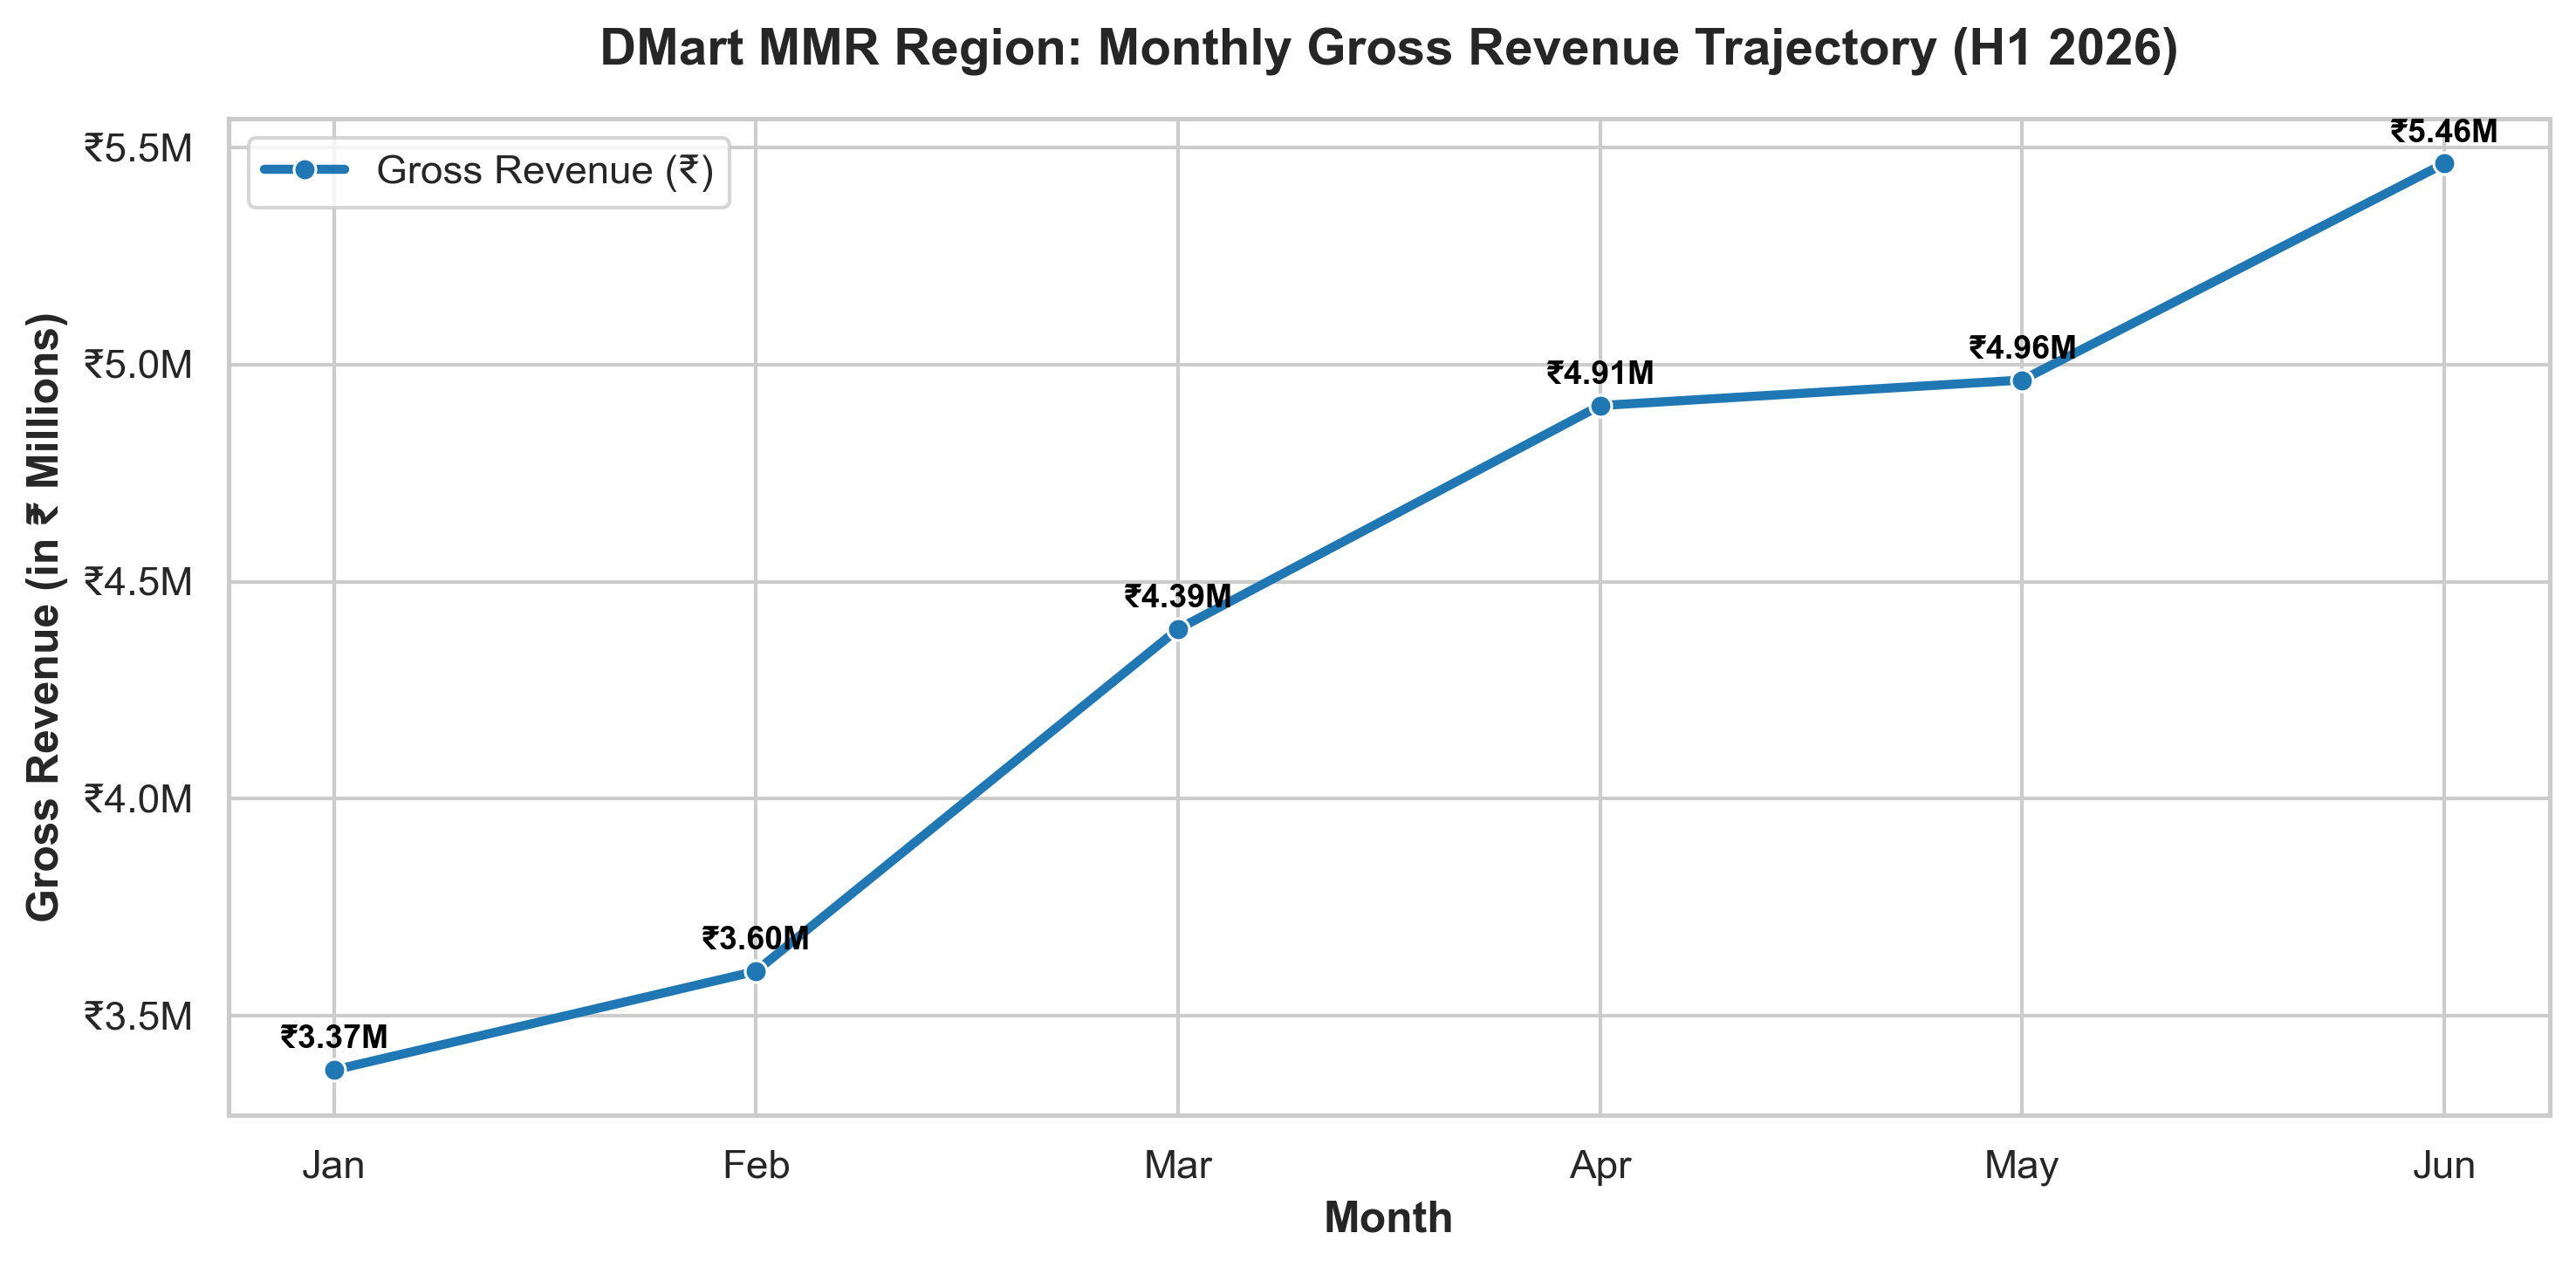

In [107]:
plt.figure(figsize=(10, 5), dpi=300)
sns.set_theme(style="whitegrid")

# Plot Gross Revenue line & markers
ax = sns.lineplot(
    data=monthly_summary, 
    x='Month_Name', 
    y='Gross_Revenue', 
    marker='o', 
    linewidth=2.5, 
    color='#1f77b4', 
    label='Gross Revenue (₹)'
)

plt.title('DMart MMR Region: Monthly Gross Revenue Trajectory (H1 2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Gross Revenue (in ₹ Millions)', fontsize=12, fontweight='bold')

# Format y-axis to display in Millions (₹M)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"₹{x*1e-6:.1f}M"))

# Annotate data points on the plot
for _, row in monthly_summary.iterrows():
    ax.text(
        row['Month_Name'], 
        row['Gross_Revenue'] + 50000, 
        f"₹{row['Gross_Revenue']*1e-6:.2f}M", 
        color='black', 
        ha='center', 
        fontsize=9, 
        weight='semibold'
    )

plt.tight_layout()
plt.legend(loc='upper left')
plt.show()

# Machine Learning 

In [114]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LinearRegression
from itertools import combinations
from collections import Counter
from sklearn.metrics import confusion_matrix

In [109]:
sns.set_theme(style="whitegrid", palette="Set2")

In [110]:
df['Full_Date'] = pd.to_datetime(
    df['Full_Date'],
    format='%d-%m-%Y',
    errors='coerce'
)


========== CUSTOMER SEGMENTATION ==========
                  Recency  Frequency  Monetary  Annual_Income
Customer_Segment                                             
Cluster 0           80.53       2.01   1642.50      551506.78
Cluster 1           10.42      11.04  39270.68     1309358.47
Cluster 2           18.41      14.53   6614.20      860600.16
Cluster 3           26.11       4.45  29048.94     2602986.66

Displaying Graph 1: Customer Segmentation


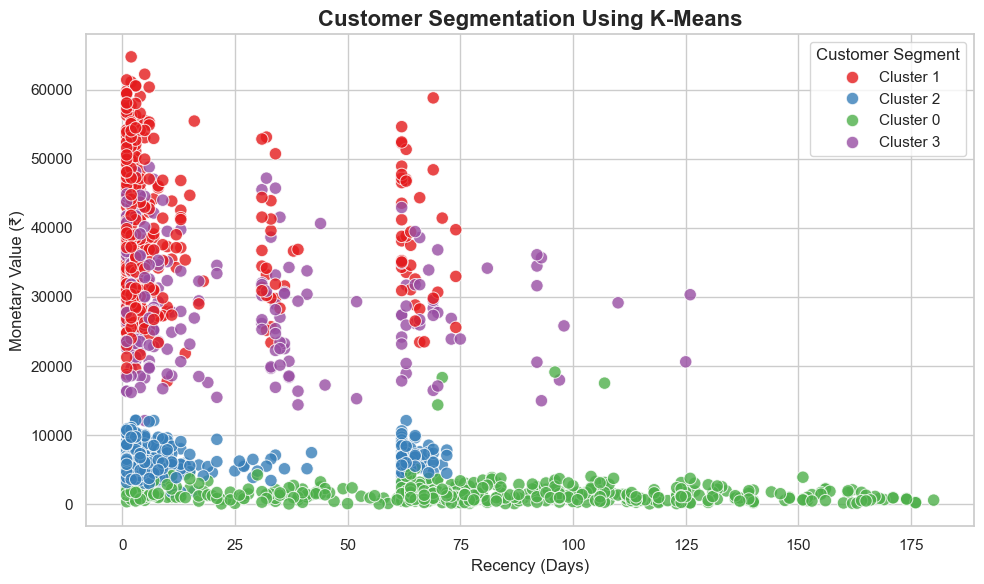

In [112]:
# ==============================================================================
# MODULE 1: RFM ANALYSIS AND K-MEANS CUSTOMER SEGMENTATION
# ==============================================================================

snapshot_date = df['Full_Date'].max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer_ID').agg(
    Recency=('Full_Date',
             lambda x: (snapshot_date - x.max()).days),

    Frequency=('Transaction_ID', 'nunique'),

    Monetary=('Gross_Amount', 'sum'),

    Avg_Order_Value=('Gross_Amount', 'mean'),

    Annual_Income=('Annual_Income', 'first'),

    Age=('Age', 'first'),

    Churn_Flag=('Churn_Flag', 'first')

).reset_index()

features_cluster = [
    'Recency',
    'Frequency',
    'Monetary',
    'Annual_Income'
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(rfm[features_cluster])

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster_ID'] = kmeans.fit_predict(X_scaled)

rfm['Customer_Segment'] = (
    'Cluster ' + rfm['Cluster_ID'].astype(str)
)

cluster_summary = rfm.groupby(
    'Customer_Segment'
)[features_cluster].mean().round(2)

print("\n========== CUSTOMER SEGMENTATION ==========")
print(cluster_summary)

# GRAPH 1: CUSTOMER SEGMENTATION

print("\nDisplaying Graph 1: Customer Segmentation")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Customer_Segment',
    palette='Set1',
    s=80,
    alpha=0.8
)

plt.title(
    'Customer Segmentation Using K-Means',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value (₹)')
plt.legend(title='Customer Segment')
plt.tight_layout()

plt.show()
plt.close()


========== CHURN PREDICTION ==========
Model Accuracy: 92.53%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.91      0.95       269
           1       0.81      0.95      0.88       106

    accuracy                           0.93       375
   macro avg       0.90      0.93      0.91       375
weighted avg       0.93      0.93      0.93       375


Churn Risk Distribution:
Churn_Risk
Low Risk       1040
High Risk       423
Medium Risk      37
Name: count, dtype: int64

Churn Feature Importance:
           Feature  Importance
0          Recency    0.669990
2         Monetary    0.102388
4    Annual_Income    0.087250
3  Avg_Order_Value    0.056292
1        Frequency    0.054601
5              Age    0.029479

Displaying Graph 2: Churn Confusion Matrix


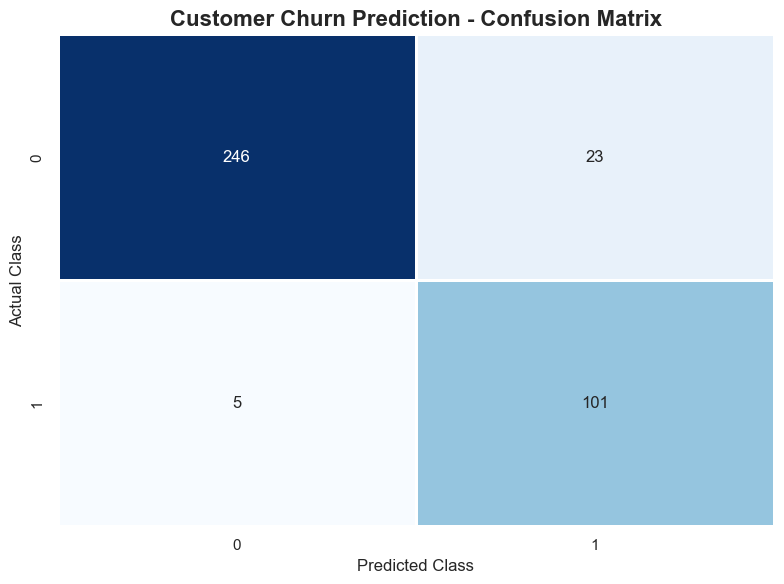


Displaying Graph 3: Churn Feature Importance


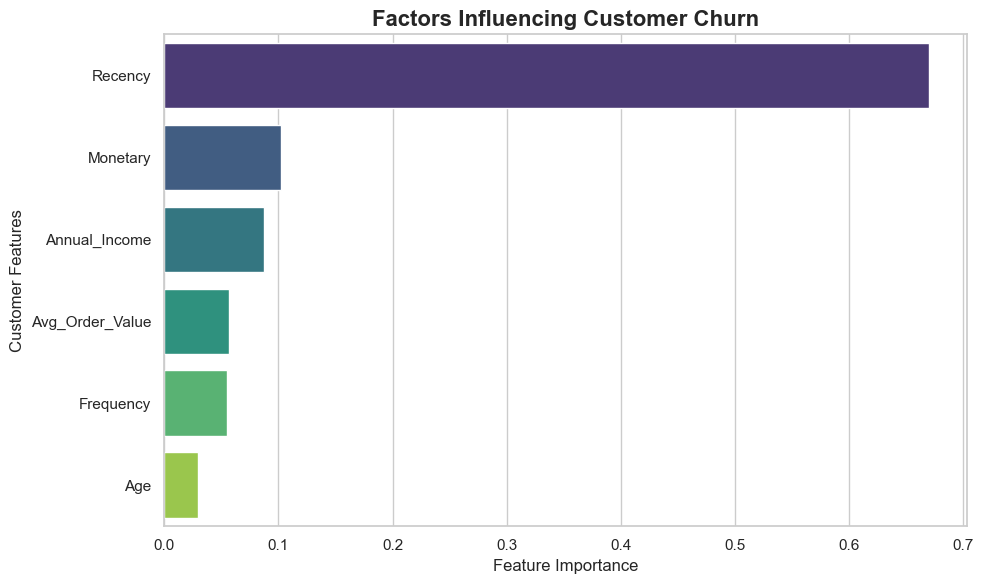

In [116]:
# ==============================================================================
# MODULE 2: CUSTOMER CHURN PREDICTION
# ==============================================================================

features = [
    'Recency',
    'Frequency',
    'Monetary',
    'Avg_Order_Value',
    'Annual_Income',
    'Age'
]

X_clf = rfm[features]
y_clf = rfm['Churn_Flag']

X_train, X_test, y_train, y_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.25,
    random_state=42,
    stratify=y_clf
)

evaluation_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

evaluation_model.fit(X_train, y_train)

y_pred = evaluation_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== CHURN PREDICTION ==========")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Train final model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_clf, y_clf)

if 1 not in rf_model.classes_:
    raise ValueError("Churn_Flag must contain class 1 for churn.")

class_1_index = list(rf_model.classes_).index(1)

rfm['Churn_Probability'] = rf_model.predict_proba(
    X_clf
)[:, class_1_index].round(3)

rfm['Churn_Risk'] = pd.cut(
    rfm['Churn_Probability'],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

print("\nChurn Risk Distribution:")
print(rfm['Churn_Risk'].value_counts())

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

print("\nChurn Feature Importance:")
print(importance_df)

# GRAPH 2: CHURN CONFUSION MATRIX

print("\nDisplaying Graph 2: Churn Confusion Matrix")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    linewidths=1
)

plt.title(
    'Customer Churn Prediction - Confusion Matrix',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()

plt.show()
plt.close()

# GRAPH 3: CHURN FEATURE IMPORTANCE

print("\nDisplaying Graph 3: Churn Feature Importance")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title(
    'Factors Influencing Customer Churn',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Feature Importance')
plt.ylabel('Customer Features')
plt.tight_layout()

plt.show()
plt.close()


========== MARKET BASKET ANALYSIS ==========
                                                 Rule  Support  Confidence   Lift
Surf Excel Matic 3kg -> Comfort Fabric Conditioner 2L   0.1502      0.6288 3.9038
Comfort Fabric Conditioner 2L -> Surf Excel Matic 3kg   0.1502      0.9322 3.9038
         Nescafe Classic Jar 200g -> Basmati Rice 5kg   0.0339      0.5286 2.7797
         Basmati Rice 5kg -> Nescafe Classic Jar 200g   0.0339      0.1782 2.7797
                  Sunflower Oil 5L -> Wheat Atta 10kg   0.2721      0.8900 2.6429
                  Wheat Atta 10kg -> Sunflower Oil 5L   0.2721      0.8081 2.6429
    Parle-G Gold Biscuits 1kg -> Tata Tea Premium 1kg   0.1261      0.8648 2.3746
    Tata Tea Premium 1kg -> Parle-G Gold Biscuits 1kg   0.1261      0.3463 2.3746
         Nescafe Classic Jar 200g -> Sunflower Oil 5L   0.0449      0.7001 2.2897
         Sunflower Oil 5L -> Nescafe Classic Jar 200g   0.0449      0.1468 2.2897

Displaying Graph 4: Market Basket Analysis


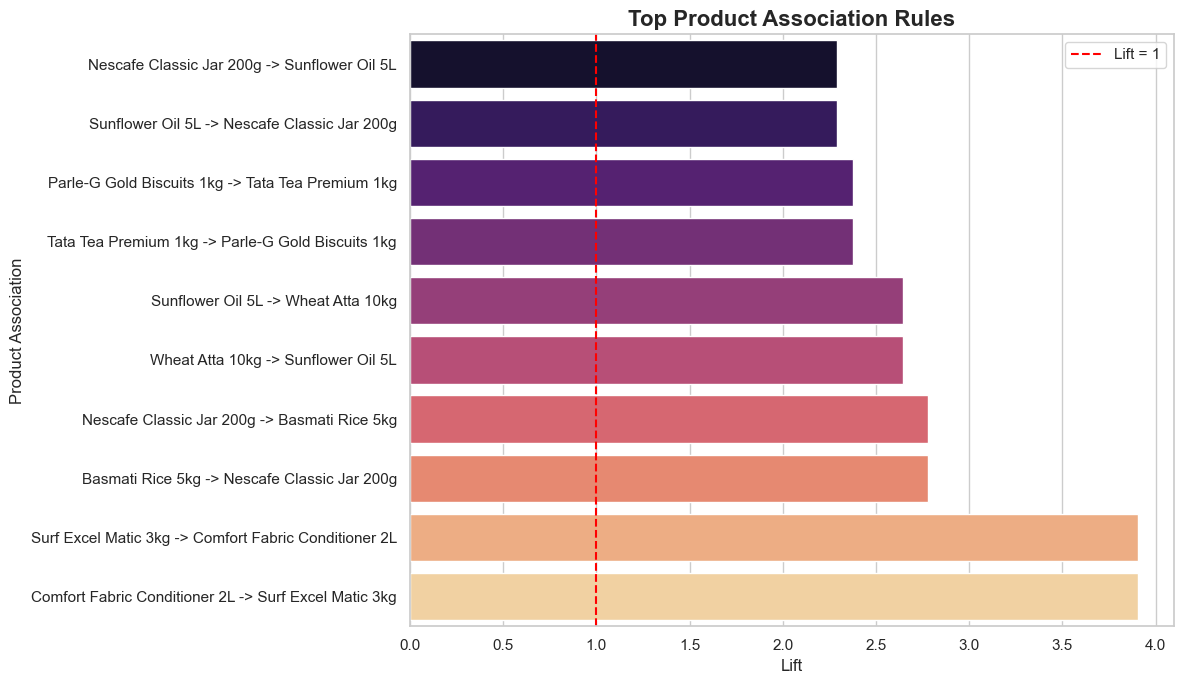

In [117]:
# ==============================================================================
# MODULE 3: MARKET BASKET ANALYSIS
# ==============================================================================

baskets = df.groupby(
    'Transaction_ID'
)['Product_Name'].apply(
    lambda x: set(x.dropna())
)

n_txns = len(baskets)

item_counts = Counter()
pair_counts = Counter()

for items in baskets:

    for item in items:
        item_counts[item] += 1

    for pair in combinations(sorted(items), 2):
        pair_counts[pair] += 1

rules = []

for (item_a, item_b), count_ab in pair_counts.items():

    support = count_ab / n_txns

    if support >= 0.03:

        confidence_ab = count_ab / item_counts[item_a]

        lift_ab = confidence_ab / (
            item_counts[item_b] / n_txns
        )

        if lift_ab > 1.2:

            rules.append({
                'Antecedent': item_a,
                'Consequent': item_b,
                'Rule': f'{item_a} -> {item_b}',
                'Support': support,
                'Confidence': confidence_ab,
                'Lift': lift_ab
            })

        confidence_ba = count_ab / item_counts[item_b]

        lift_ba = confidence_ba / (
            item_counts[item_a] / n_txns
        )

        if lift_ba > 1.2:

            rules.append({
                'Antecedent': item_b,
                'Consequent': item_a,
                'Rule': f'{item_b} -> {item_a}',
                'Support': support,
                'Confidence': confidence_ba,
                'Lift': lift_ba
            })

rules_df = pd.DataFrame(rules)

if not rules_df.empty:

    rules_df = rules_df.sort_values(
        by=['Lift', 'Confidence'],
        ascending=False
    ).head(10)

    rules_df = rules_df.round(4)

    print("\n========== MARKET BASKET ANALYSIS ==========")

    print(
        rules_df[
            ['Rule', 'Support', 'Confidence', 'Lift']
        ].to_string(index=False)
    )

    # GRAPH 4: MARKET BASKET ANALYSIS

    print("\nDisplaying Graph 4: Market Basket Analysis")

    plt.figure(figsize=(12, 7))

    basket_plot = rules_df.sort_values(
        'Lift',
        ascending=True
    )

    sns.barplot(
        data=basket_plot,
        x='Lift',
        y='Rule',
        hue='Rule',
        palette='magma',
        legend=False
    )

    plt.axvline(
        1,
        color='red',
        linestyle='--',
        label='Lift = 1'
    )

    plt.title(
        'Top Product Association Rules',
        fontsize=16,
        fontweight='bold'
    )

    plt.xlabel('Lift')
    plt.ylabel('Product Association')
    plt.legend()
    plt.tight_layout()


    plt.show()
    plt.close()

else:

    print("\nNo qualifying association rules found.")



========== SALES FORECASTING ==========

Historical Monthly Sales:
  Month  Gross_Amount
2026-01    3374782.80
2026-02    3602408.40
2026-03    4390527.40
2026-04    4905524.25
2026-05    4964376.50
2026-06    5463045.65

Predicted July 2026 Revenue: ₹5,954,332.37

Displaying Graph 5: July Sales Forecast


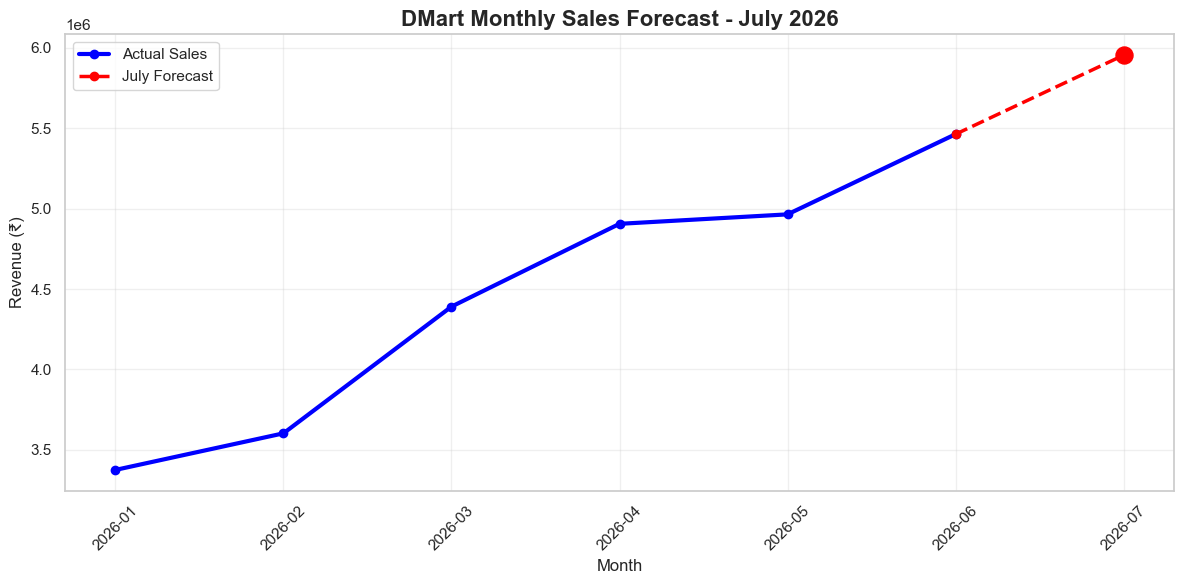

In [118]:

# ==============================================================================
# MODULE 4: SALES FORECASTING - JULY 2026
# ==============================================================================

TARGET_MONTH = pd.Period('2026-07', freq='M')

df['Sales_Month'] = df['Full_Date'].dt.to_period('M')

monthly_sales = (
    df.groupby('Sales_Month')['Gross_Amount']
    .sum()
    .sort_index()
)

training_sales = monthly_sales[
    monthly_sales.index < TARGET_MONTH
]

if len(training_sales) < 2:
    raise ValueError("Insufficient historical sales data.")

all_months = pd.period_range(
    start=training_sales.index.min(),
    end=TARGET_MONTH - 1,
    freq='M'
)

sales_series = training_sales.reindex(
    all_months,
    fill_value=0
)

sales_df = pd.DataFrame({
    'Month': sales_series.index.astype(str),
    'Gross_Amount': sales_series.values,
    'Month_Index': np.arange(1, len(sales_series) + 1)
})

reg = LinearRegression()

reg.fit(
    sales_df[['Month_Index']],
    sales_df['Gross_Amount']
)

july_index = len(sales_df) + 1

july_pred = reg.predict(
    pd.DataFrame({
        'Month_Index': [july_index]
    })
)[0]

july_pred = max(0, july_pred)

print("\n========== SALES FORECASTING ==========")

print("\nHistorical Monthly Sales:")
print(sales_df[['Month', 'Gross_Amount']].to_string(index=False))

print(
    f"\nPredicted July 2026 Revenue: ₹{july_pred:,.2f}"
)

# GRAPH 5: SALES FORECASTING

print("\nDisplaying Graph 5: July Sales Forecast")

plt.figure(figsize=(12, 6))

plt.plot(
    sales_df['Month'],
    sales_df['Gross_Amount'],
    marker='o',
    linewidth=3,
    color='blue',
    label='Actual Sales'
)

plt.plot(
    ['2026-06', '2026-07'],
    [
        sales_df['Gross_Amount'].iloc[-1],
        july_pred
    ],
    marker='o',
    linestyle='--',
    linewidth=2.5,
    color='red',
    label='July Forecast'
)

plt.scatter(
    '2026-07',
    july_pred,
    color='red',
    s=150,
    zorder=5
)

plt.title(
    'DMart Monthly Sales Forecast - July 2026',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()


plt.show()
plt.close()



Displaying Graph 6: Churn Risk Distribution


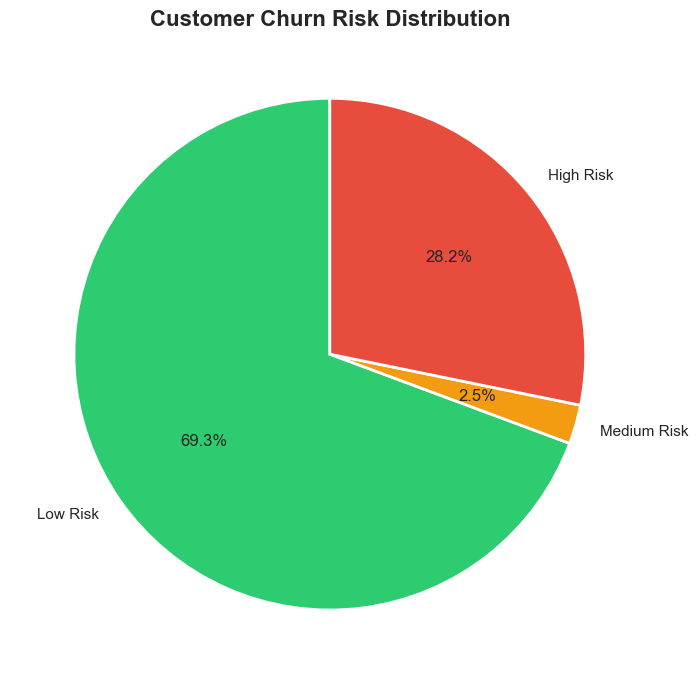

In [119]:

# ==============================================================================
# MODULE 5: CUSTOMER CHURN RISK DISTRIBUTION
# ==============================================================================

risk_counts = (
    rfm['Churn_Risk']
    .value_counts()
    .reindex(
        ['Low Risk', 'Medium Risk', 'High Risk'],
        fill_value=0
    )
)

# GRAPH 6: CHURN RISK DISTRIBUTION

print("\nDisplaying Graph 6: Churn Risk Distribution")

plt.figure(figsize=(8, 7))

colors = ['#2ECC71', '#F39C12', '#E74C3C']

plt.pie(
    risk_counts.values,
    labels=risk_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 2
    }
)

plt.title(
    'Customer Churn Risk Distribution',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()


plt.show()
plt.close()


# Strategic Business Recommendations

## Targeted Retention Campaigns (Random Forest Churn Insights)

### Finding:
- The Random Forest model identified that **28.2% of customers** fall into the High-Risk Churn category.
- Recency emerged as the dominant predictor of customer inactivity, contributing approximately **67% feature importance**.

### Actionable Strategy:
1. **Automated CRM Triggers:** Implement automated WhatsApp and SMS notifications through the DMart Ready mobile application for customers crossing a 30-day inactivity threshold.
2. **Personalized Retention Offers:** Introduce targeted "We Miss You" incentives, such as ₹100 off on purchases above ₹1,000 in high-demand staple categories.
3. **Customer Prioritization:** Focus retention campaigns on high-value shoppers exhibiting early signs of churn.

### Expected Business Impact:
Reduced customer churn, improved repeat purchase rates, and increased customer lifetime value (CLV).

---

## Store Layout and Cross-Merchandising Optimization (Apriori Market Basket Insights)

### Finding:
- Association Rule Mining identified strong product associations.
- Surf Excel Matic 3kg and Comfort Fabric Conditioner 2L demonstrated a Lift value of approximately **3.9**.
- Additional complementary associations were identified across cooking oils and beverages.

### Actionable Strategy:
1. **Adjacency Merchandising:** Position fabric softeners and liquid detergents in adjacent shelf sections across MMR hypermarkets, including Dadar, Thane, and Borivali.
2. **Digital Bundling:** Introduce dynamic combo discounts on the DMart Ready application when customers simultaneously add high-lift product combinations to their shopping carts.
3. **Cross-Selling Optimization:** Use identified product associations to design targeted in-store promotional displays.

### Expected Business Impact:
Increased basket size, higher average transaction value, and improved cross-category sales.

---

## Tiered Loyalty and Promotional Strategy (K-Means Segmentation)

### Finding:
- K-Means clustering segmented MMR customers into distinct behavioral groups using Recency, Frequency, and Monetary (RFM) metrics.
- The segmentation differentiated high-spending loyal customers from occasional and price-sensitive shoppers.

### Actionable Strategy:
1. **Protect High-Value Loyalists (Cluster 1):**
   - Introduce priority checkout facilities.
   - Provide dedicated parking assistance.
   - Offer exclusive weekend early-access sales to top-tier members.

2. **Upsell Mid-Tier Shoppers:**
   - Implement milestone-based reward programs.
   - Introduce incentives such as "Spend ₹500 more to unlock Silver Tier grocery benefits."
   - Encourage increased purchase frequency and average order value (AOV).

### Expected Business Impact:
Improved customer loyalty, increased customer spending, and stronger long-term customer relationships.

---

## Supply Chain and Inventory Scaling (Linear Regression Sales Forecast)

### Finding:
- The Linear Regression model projects continued upward sales momentum.
- Estimated gross revenue is projected to reach **₹5.8 million in July 2026**, compared with ₹3.3 million in January and ₹5.3 million in June 2026.

### Actionable Strategy:
1. **Inventory Buffer Management:**
   - Pre-position high-turnover FMCG products and essential staple inventories at MMR distribution hubs.
   - Maintain adequate inventory levels ahead of anticipated July demand.
   - Minimize stockouts during high-demand weekend retail periods.

2. **Staffing Optimization:**
   - Dynamically schedule floor staff and checkout operators based on predicted customer traffic.
   - Allocate additional workforce during Friday-to-Sunday peak hours.
   - Optimize checkout operations to reduce waiting times.

### Expected Business Impact:
Reduced inventory shortages, improved operational efficiency, optimized workforce utilization, and increased sales revenue.

---

## Overall Strategic Business Impact

The integration of machine learning, predictive analytics, and data-driven decision-making enables DMart to transform analytical insights into actionable business strategies across its Mumbai Metropolitan Region operations.

| Analytical Technique | Business Application | Expected Outcome |
|:---|:---|:---|
| Random Forest | Customer churn prediction | Improved customer retention |
| Apriori Algorithm | Product association analysis | Increased cross-selling |
| K-Means Clustering | Customer segmentation | Improved loyalty and AOV |
| Linear Regression | Sales forecasting | Optimized inventory and staffing |

### Conclusion:

By implementing these data-driven recommendations, DMart can strengthen customer retention, optimize store-level merchandising, enhance promotional effectiveness, and improve supply chain efficiency across the Mumbai Metropolitan Region. These strategies collectively support sustainable revenue growth, operational excellence, and higher customer satisfaction.
